# When Prediction Fails
 
## 가진 게 망치뿐이라면...
2015년부터 2020년 사이 머신러닝은 폭발적으로 성장했습니다. 컴퓨터 비전과 자연어 이해 분야에서 쓸모가 입증된 데다 초기에는 이 분야 전문가가 부족했던 덕분에, 머신러닝 교육 산업이 자라기에 더없이 좋은 환경이 만들어졌습니다. Andrew Ng, Sebastian Thrun 같은 인물들은 헐값에 가까운 비용으로 전 세계에 머신러닝을 가르쳤습니다. 소프트웨어 쪽에서도 복잡한 머신러닝 모델을 학습시키는 일이 점점 쉬워졌습니다(앞 장에서 머신러닝 모델 하나를 만드는 데 코드 몇 줄이면 충분했던 것을 이미 보셨을 겁니다). 지능형 시스템을 만드는 튜토리얼이 인터넷 곳곳에 쏟아졌고, 머신러닝에 입문하는 비용은 곤두박질쳤습니다.

![img](./data/img/when-prediction-fails/ml-in-5.png)
 
머신러닝 모델을 만드는 일이 너무 간단해져서 코딩을 썩 잘할 필요도(제가 그 산증인입니다), 알고리즘 뒤에 숨은 수학을 알 필요도 없어졌습니다. 실제로 아래 파이썬 다섯 줄이면 놀라운 것들을 만들 수 있었습니다.
 
```python
X_train, y_train, X_test, y_test =  train_test_split(X, y)
 
## instantiate the machine learning model
model = MachineLearningModel()
 
## Fit the ML model
model.fit(X_train, y_train)
 
# Make predictions on unseen data
y_pred = model.predict(X_test)
 
# Evaluate the quality of predictions
print("Performance", metric(y_test, y_pred))
```
 
대체로 이건 정말 멋진 일입니다! 가치 있는 지식을 누구나 쓸 수 있게 만드는 일이라면 저는 전적으로 찬성입니다. 하지만 여기에는 어두운 면도 있습니다. 새로 등장한 데이터 과학자 세대는 주로 예측 모델링을 배웠습니다. 머신러닝이 주로 풀려는 문제가 예측이기 때문입니다. 그 결과 이들은 비즈니스 문제를 만날 때마다, 놀랄 것도 없이 예측 모델로 덤벼들었습니다. 앞 장에서 본 것처럼 정말 예측 문제였다면 대개 성공했고 모두가 행복했습니다. 그런데 예측 기법으로는 아예 풀 수 없는 문제들이 한 부류 통째로 있습니다. 그런 문제가 나타나면 데이터 과학자들은 대개 처참하게 실패했습니다. 바로 'X를 바꿔서 Y를 얼마나 늘릴 수 있을까'라는 형태의 문제들입니다.
 
제 경험상 경영진이 가장 신경 쓰는 쪽은 대개 이 두 번째 유형의 문제입니다. 경영진은 매출을 늘리고, 비용을 줄이고, 고객을 더 끌어오는 방법을 알고 싶어 합니다. 데이터 과학자가 매출을 늘리는 방법이 아니라 매출을 예측하는 방법을 답이라고 들고 오면 경영진이 별로 반기지 않으리라는 건 말할 필요도 없습니다. 안타깝게도 데이터 과학자가 아는 것이 예측 모델뿐이면 이런 일이 자주 벌어집니다. 예전 상사가 제게 이런 말을 한 적이 있습니다. "가진 게 망치뿐이면 모든 게 엄지손가락으로 보이기 시작한다."
 
앞서 말했듯 저는 지식의 문턱을 낮추는 데 전적으로 찬성하지만, 지금의 데이터 과학자 교육 과정에는 큰 구멍이 있습니다. 그 구멍을 메우는 것이 이 책에서 제가 할 일이라고 생각합니다. 본질적으로 인과적인 이 다른 부류의 문제를 풀 도구를 여러분 손에 쥐여 드리는 것이죠.

여기서 하려는 일은 내가 통제할 수 있는 것(광고, 가격, 고객 서비스)이 바꾸고 싶지만 직접 통제할 수는 없는 것(매출, 고객 수, 손익)에 어떤 영향을 미치는지, 다시 말해 그 변화를 어떻게 일으키는지 추정하는 것입니다. 하지만 이런 문제를 푸는 방법을 보여 드리기 전에, 이 문제를 예측 과제처럼 다뤄 전통적인 머신러닝 도구로 풀려고 하면 어떤 일이 벌어지는지 먼저 보여 드리려 합니다. 데이터 과학자들이 종종 저를 찾아와 이렇게 말하기 때문입니다. "네, 인과 문제를 예측 도구로 푸는 게 최선이 아니라는 건 알겠어요. 그래도 어느 정도는 도움이 되지 않나요? 그러니까, 손해 볼 건 없잖아요..." 그런데 알고 보면 손해를 볼 수 있습니다. 그러니 계속 자기 엄지를 망치로 내리치기 전에 이 점을 제대로 이해해 두는 편이 좋습니다.

![img](./data/img/when-prediction-fails/horse-meme.png)

> 옮긴이: 상사의 말은 '망치를 든 사람에게는 모든 것이 못으로 보인다'는 격언을 비튼 것입니다. 못 대신 자기 엄지를 내리치게 된다는 농담입니다.

In [1]:
import pandas as pd
import numpy as np
from sklearn import ensemble
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.ensemble import gradient_boosting
from sklearn.metrics import r2_score
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import style
style.use("ggplot")

# helper functions for this notebook
from nb18 import ltv_with_coupons

## 쿠폰 받으실 분?
 
조금 더 와닿게 하려고 앞 장에서 쓴 예제를 이어 가되, 살짝 비틀어 보겠습니다. 앞 장에서는 수익이 나는 고객과 그렇지 않은 고객을 구별하려 했습니다. 이를 고객 수익성을 예측하는 예측 문제로 정의했습니다. 그러고 나서 이 과제를 위한 머신러닝 모델을 만들고, 그 모델로 거래할 고객, 즉 수익이 날 것으로 예측된 고객만 골라낼 수 있었습니다. 다시 말해 목표는 수익이 나는 고객과 나지 않는 고객을 가르는 것이었고, 예측 모델로 그 일을 해낼 수 있었습니다.
 
이번에는 새 과제가 주어졌습니다. 신규 고객에게 쿠폰을 주면 고객의 참여가 늘고 장기적으로 수익성이 높아질 것 같다는 생각이 듭니다. 고객이 돈을 더 많이, 더 오래 쓴다는 뜻입니다. 새로 맡은 일은 쿠폰 금액을 얼마로 할지(0 포함) 정하는 것입니다. 쿠폰을 준다는 건 사실상 고객이 우리 비즈니스에서 쓸 돈을 공짜로 나눠 주는 셈이라는 점에 주목하세요. 그래서 쿠폰은 장부에 비용으로 잡힙니다. 쿠폰 금액이 너무 크면 고객이 필요한 것을 전부 쿠폰만으로 사 버릴 테니 아마 손해를 볼 것입니다. 제품을 공짜로 가져간다는 말을 달리 한 것뿐이죠. 반대로 쿠폰 금액이 너무 작으면(또는 0이면) 쿠폰을 아예 주지 않는 것과 같습니다. 이것도 정답일 수 있지만, 처음에 쿠폰 형태로 약간 할인해 주는 편이 장기적으로 더 이익일 수도 있습니다.
 
나중에 알게 될 이유로, 고정된 데이터셋을 불러오는 대신 데이터 생성 함수를 쓰겠습니다. `ltv_with_coupons` 함수가 거래 데이터를 만들어 줍니다. 보다시피 앞에서 본 데이터와 형식이 같습니다. 고객당 한 행이고, 획득 비용 열 하나와 1일부터 30일까지의 거래 열이 있습니다.

In [2]:
transactions, customer_features = ltv_with_coupons()

print(transactions.shape)
transactions.head()

(10000, 32)


,customer_id,cacq,day_0,day_1,day_2,day_3,day_4,day_5,day_6,day_7,...,day_20,day_21,day_22,day_23,day_24,day_25,day_26,day_27,day_28,day_29
0,0,-110,0,0,0,0,5,0,2,2,...,0,3,0,4,0,0,0,0,0,0
1,1,-61,2,0,5,2,3,4,1,0,...,5,0,1,35,11,0,5,2,4,0
2,2,-8,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,-30,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,-41,0,0,0,2,0,4,0,0,...,0,0,0,0,0,0,0,0,0,0


나머지 데이터에도 마찬가지로 고객 식별자, 고객이 사는 지역, 소득, 나이가 있습니다. 여기에 더해 이번에는 `coupons` 변수가 생겼습니다. 해당 고객에게 쿠폰을 얼마나 주었는지를 나타냅니다.

In [3]:
print(customer_features.shape)
customer_features.head()

(10000, 5)


,customer_id,region,income,coupons,age
0,0,18,1025,5,24
1,1,40,1649,5,26
2,2,35,2034,15,33
3,3,29,1859,15,35
4,4,11,1243,5,26


이 데이터를 하나의 데이터프레임으로 정리하기 위해 첫 번째 테이블의 모든 열을 더하겠습니다(즉, `CACQ`와 거래 금액을 합칩니다). 그러면 앞 장에서 계산한 것과 같은 `net_value`가 나옵니다. 그다음 특성 데이터를 조인하고, 쿠폰 비용을 반영하도록 `net_value`를 갱신합니다.

In [4]:
def process_data(transactions, customer_data):

    profitable = (transactions[["customer_id"]]
                  .assign(net_value = transactions
                          .drop(columns="customer_id")
                          .sum(axis=1)))

    return (customer_data
            # join net_value and features
            .merge(profitable, on="customer_id")
            # include the coupons cost
            .assign(net_value = lambda d: d["net_value"] - d["coupons"]))

customer_features = process_data(transactions, customer_features)
customer_features.head()

,customer_id,region,income,coupons,age,net_value
0,0,18,1025,5,24,-44
1,1,40,1649,5,26,74
2,2,35,2034,15,33,-23
3,3,29,1859,15,35,-45
4,4,11,1243,5,26,-26


이렇게 정리한 데이터프레임에는 필요한 것이 모두 들어 있습니다. 목표 변수인 `net_value`, 고객 특성인 `region`, `income`, `age`, 그리고 최적화하려는 조정 수단, 즉 처치(treatment)인 쿠폰이 있습니다. 쿠폰이 `net_value`를 어떻게 늘릴 수 있는지 감을 잡기 위해, 먼저 쿠폰이 어떻게 지급되었는지 살펴보겠습니다.

In [5]:
customer_features.groupby("coupons")["customer_id"].count()

coupons
0      458
5     4749
10    4154
15     639
Name: customer_id, dtype: int64

지급된 쿠폰은 대부분 5 BRL짜리였고, 그다음이 10 BRL짜리였습니다. 15 BRL 쿠폰을 주거나 쿠폰을 아예 주지 않은(금액 0) 경우는 아주 적었습니다. 쿠폰이 무작위로 지급되지 **않았다는** 신호입니다. 이를 확인하기 위해 다른 변수들과 쿠폰 사이의 상관관계를 보겠습니다.

In [6]:
customer_features.corr()[["coupons"]]

,coupons
customer_id,0.002239
region,-0.004073
income,0.001236
coupons,1.000000
age,0.897308
net_value,-0.078369


흥미롭네요. 나이가 많을수록 쿠폰을 받을 확률이 높은 것 같습니다. 데이터에 편향(bias)이 있다는 신호입니다. 쿠폰과 `net_value` 사이에는 음의 상관관계도 보입니다. 쿠폰을 많이 줄수록 net_value가 작습니다. 쿠폰이 무작위로 지급되지 않았다는 걸 이미 알고 있으니 이 관계를 인과관계로 보기는 어렵습니다. 예를 들어 나이 든 고객이 우리 제품에 돈을 덜 쓰면서 동시에 더 큰 쿠폰을 받는다면, 이 교란(confounding) 때문에 쿠폰과 `net_value`의 관계가 음수로 보일 정도로 왜곡될 수 있습니다.

요점은 편향이 있다는 걸 우리가 안다는 것입니다. 다만 이 장에는 이미 담을 내용이 너무 많으니 지금은 무시하겠습니다(사실은 곧 보게 될 장치를 써서 이 문제를 비켜 가겠습니다). 언젠가는 해결해야 할 문제라는 점만 기억해 두세요.

분석이 이 단계에 이르렀을 때 **예측 문제라면** 데이터셋을 학습용과 테스트용으로 나눠 각각 정책(policy)을 만들고 평가할 것입니다. 하지만 이건 예측 문제가 아닙니다. 최종 목표는 고객 수익성을 잘 예측하는 것이 아니라 최적의 쿠폰 전략을 찾는 것입니다. 이 최적화를 평가하려면 실제로 준 쿠폰과 다른 쿠폰을 주었다면 어떻게 되었을지 알아야 합니다. 지금까지 인과관계를 다루며 공부해 온 '만약 ~였다면'이라는 반사실(counterfactual) 질문이 바로 이런 것입니다. 반사실은 아예 관측할 수 없으니 교차 검증(cross validation)도 여기서는 도움이 되지 않습니다. 실제로 준 쿠폰에 대해 일어난 일만 볼 수 있을 뿐, 고객이 다른 금액의 쿠폰을 받았다면 어떻게 되었을지는 알 수 없습니다. 시뮬레이션 데이터가 아니라면 말이죠!

데이터가 시뮬레이션된 것이라면 쿠폰 금액 매개변수만 바꿔서 완전히 똑같은 데이터를 생성할 수 있습니다. 그러면 쿠폰 전략에 따라 `net_value`가 어떻게 달라지는지 볼 수 있고, 전략 간 처치효과(treatment effect) $NetValue_{t=a} - NetValue_{t=b}$도 계산할 수 있습니다. 시뮬레이션 데이터의 힘을 빌리면 이 장을 이해하기가 훨씬 쉬워집니다. 아, 그리고 인과효과를 직접 관측하게 되니 편향 문제도 신경 쓸 필요가 없어집니다.

그렇지만 이건 어디까지나 교육용 장치라는 점을 늘 기억하세요. 현실에는 시뮬레이션 데이터가 없고, 다른 처치 전략을 썼다면 어떻게 되었을지 볼 수도 없습니다. 개별 인과효과는 언제나 그랬듯 가려져 있습니다. 여기서 흥미로운 문제가 생깁니다. 실제 인과효과를 결코 볼 수 없다면, 인과효과를 찾아내는 전략은 어떻게 평가할 수 있을까요? 진짜 답은 꽤 복잡하고, 따로 한 장을 할애할 만큼 중요합니다. 반드시 다룰 테니 안심하세요. 지금은 시뮬레이션 데이터의 단순함을 즐기면 됩니다. 단순함 이야기가 나온 김에...


## 단순한 정책

늘 그렇듯 새로운 데이터 문제를 만나면 가장 먼저 '당장 가치를 낼 수 있는 가장 단순한 방법은 무엇일까?'라고 스스로 물어야 합니다. 이 경우 가장 단순한 방법은 가진 데이터를 돌아보며 쿠폰 금액별로 `net_value`를 추정하는 것입니다. 그런 다음 어떤 쿠폰 금액이 가장 높은 `net_value`를 내는지 확인하고, 모든 고객에게 그 금액의 쿠폰만 주면 됩니다.

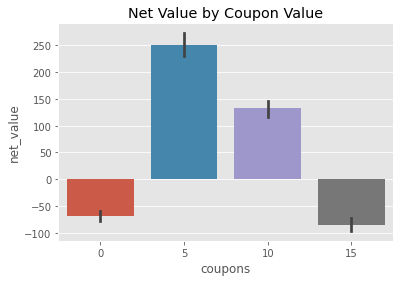

In [7]:
sns.barplot(data=customer_features, x="coupons", y="net_value")
plt.title("Net Value by Coupon Value");

분석해 보면 쿠폰 금액이 0이나 15일 때는 평균적으로 손해를 보고, 5 BRL과 10 BRL일 때는 이익을 냅니다. 평균 `net_income`이 가장 높은 것은 5 BRL 쿠폰으로, 고객당 약 250 BRL의 `net_value`를 냅니다. 그러니 자연스럽게 떠오르는 가장 단순한 시도는 모든 고객에게 5 BRL 쿠폰을 주고 결과를 지켜보는 것입니다. 편향 가능성은 완전히 무시하는 셈이지만, 뭐 어떻습니까. 지금은 단순함이 우선입니다!

이 정책을 평가할 수 있도록 `ltv_with_coupons` 함수는 데이터베이스에 있는 고객 10000명 각각에게 줄 쿠폰 금액을 담은 길이 10000짜리 배열을 인수로 받습니다. 이 배열을 만들려면 `np.ones`로 `coupons` 배열과 같은 크기(10000)의 1로 채운 배열을 만들고 5를 곱합니다. 그다음 이 배열을 `ltv_with_coupons`에 넘기면, 앞서 본 데이터와 똑같되 모든 쿠폰 금액이 5인 새 데이터셋이 생성됩니다. 이 데이터를 정리하면 새로 제안한 정책에서의 순가치를 구할 수 있습니다.

In [8]:
simple_policy = 5 * np.ones(customer_features["coupons"].shape)

transactions_simple_policy, customer_features_simple_policy = ltv_with_coupons(simple_policy)
customer_features_simple_policy = process_data(transactions_simple_policy, customer_features_simple_policy)

customer_features_simple_policy.head()

,customer_id,region,income,coupons,age,net_value
0,0,18,1025,5,24,-44
1,1,40,1649,5,26,74
2,2,35,2034,5,33,63
3,3,29,1859,5,35,63
4,4,11,1243,5,26,-26


검산 삼아 앞쪽 고객 몇 명의 특성이 정말 그대로인지 확인해 봅시다. 세 번째 고객(`customer_id` 2)을 예로 들어 보겠습니다. 이 고객의 지역은 35, 소득은 2034, 나이는 33입니다. 조금 위로 올려 보면 앞에서 본 값과 일치하니 문제없습니다. 쿠폰이 모두 5 BRL인지도 확인할 수 있습니다. `net_value`도 예상대로 바뀌었습니다. 한 가지 이유는 쿠폰에 드는 비용이 달라졌기 때문입니다. 예를 들어 이 고객은 원래 쿠폰을 15 BRL 받았지만 이제는 5 BRL을 받습니다. 그러면 비용이 15에서 5로 줄어듭니다. 그런데 `net_value`는 -23에서 63으로, 86 BRL이나 늘었습니다. 비용 차이 10보다 훨씬 큽니다. 이 고객은 쿠폰을 덜 받았더니 오히려 이전보다 수익성이 훨씬 높아진 것입니다. 끝으로 정책을 평가하려면 `net_value`의 평균만 구하면 됩니다.

In [9]:
simple_policy_gain = customer_features_simple_policy["net_value"].mean()
simple_policy_gain

252.9268

보다시피 이 단순한 정책에 따르면 모든 고객에게 5 BRL 쿠폰을 줄 때 고객당 평균 253 BRL을 벌 수 있습니다. 엄청나네요! 그런데 더 잘할 수는 없을까요? 이 문제에 반짝이는 머신러닝 망치를 휘둘러 보면 어떨까요? 바로 해 보겠습니다.


## 모델을 활용한 정책

머신러닝을 쓰기 위해 앞 장에서 한 작업을 응용하겠습니다. 아이디어는 앞 장처럼 `net_value`를 예측하는 머신러닝 모델을 만들고, 그 예측값을 정해진 개수의 밴드로 나누는 것입니다. 그런 다음 데이터를 그 밴드에 따라 분할합니다. 본질적으로 고객을 예측된 `net_value`로 나누는 것입니다. `net_value`를 대략 비슷하게 낼 것으로 보이는 고객들이 같은 구간, 즉 같은 그룹에 묶입니다. 마지막으로 그룹마다 어떤 쿠폰 금액이 `net_value`를 최대로 만드는지 확인합니다. 단순한 정책과 같은 일을 하되, 이번에는 예측 밴드로 정한 그룹 안에서 하는 것입니다.

![img](./data/img/when-prediction-fails/partitions.png)

이렇게 하는 이유는 다음과 같습니다. 평균적으로는 5 BRL 쿠폰의 성과가 가장 좋았다는 걸 압니다. 하지만 어떤 고객 그룹에서는 5 BRL보다 나은 금액이 있을 수 있습니다. 5 BRL이 대부분의 고객에게는 최적의 전략이지만 모든 고객에게 그렇지는 않을 수도 있습니다.

![img](./data/img/when-prediction-fails/personalise.png)

최적 금액이 다른 고객을 찾아낼 수 있다면, 위에서 만든 단순한 전략보다 나은 쿠폰 전략을 세울 수 있습니다.

이런 문제를 개인화(personalization) 문제라고 합니다. 선택할 수 있는 전략이 둘 이상이고, 그중 적어도 하나가 전체로 보면 최선이 아니지만 대상 집단의 일부에서는 최선일 때 개인화를 활용할 수 있습니다. 정의가 좀 복잡하지만 직관은 간단합니다. 전략이 하나뿐이라면 개인화가 아닙니다. 모든 고객에게 똑같이 하는 것이니까요. 전략이 여럿이더라도 그중 하나가 고객 한 명 한 명 모두에게 더 낫다면 굳이 개인화할 이유가 있을까요? 그 최선의 전략 하나만 쓰면 됩니다. 개인화는 어떤 전략이 집단의 한 부분에서 더 잘 통하고, 다른 전략이 다른 부분에서 더 잘 통할 때만 합니다.

다시 예제로 돌아갑시다. 먼저 예측 모델을 학습시키고 예측값을 예측 밴드로 나누는 함수가 필요합니다. 이 함수는 또 다른 함수, 즉 데이터프레임을 받아 예측값 열과 밴드 열을 추가하는 예측 함수를 반환합니다.

In [10]:
def model_bands(train_set, features, target, model_params, n_bands, seed=1):
    
    np.random.seed(seed)
    
    # train the ML model
    reg = ensemble.GradientBoostingRegressor(**model_params)
    reg.fit(train_set[features], train_set[target])
    
    # fit the bands
    bands = pd.qcut(reg.predict(train_set[features]), q=n_bands, retbins=True)[1]
    
    def predict(test_set):
        # make predictions with trained model
        predictions = reg.predict(test_set[features])
        
        # discretize predictions into bands.
        pred_bands = np.digitize(predictions, bands, right=False) 
        return test_set.assign(predictions=predictions,
                               # cliping avoid creating new upper bands
                               pred_bands=np.clip(pred_bands, 1, n_bands))
    
    return predict

예측의 품질을 평가하기 위해 데이터셋을 학습용과 테스트용으로 나누겠습니다. 여기서 평가하는 것은 정책이 **아니라** 예측의 품질이라는 점에 주목하세요. 모델이 원래 맡은 일을 제대로 하는지 보려는 것뿐입니다.

In [11]:
train, test = train_test_split(customer_features, test_size=0.3, random_state=1)

이제 모델을 학습시키고 그 예측값으로 밴드 10개를 만들어 보겠습니다.

In [12]:
model_params = {'n_estimators': 150,
                'max_depth': 4,
                'min_samples_split': 10,
                'learning_rate': 0.01,
                'loss': 'ls'}

features = ["region", "income", "age"]
target = "net_value"

np.random.seed(1)
model = model_bands(train, features, target, model_params, n_bands=10)

학습한 모델에 데이터프레임을 넘기면 예측을 할 수 있습니다. 결과도 데이터프레임이며, `predictions`와 `pred_bands`라는 새 열 2개가 붙어 나옵니다.

In [13]:
model(train).head()

,customer_id,region,income,coupons,age,net_value,predictions,pred_bands
2228,2228,30,567,5,27,-129,-16.296297,2
5910,5910,32,647,5,25,-55,-16.296297,2
1950,1950,31,2953,15,33,-142,102.237797,7
2119,2119,1,2860,5,27,-23,94.291197,7
5947,5947,49,589,5,26,-91,-3.525593,3


모델의 예측력을 보기 위해 학습 데이터와 테스트 데이터 각각에서 $R^2$를 확인해 보겠습니다.

In [14]:
print("Train Score:, ", r2_score(train["net_value"], model(train)["predictions"]))
print("Test Score:, ", r2_score(test["net_value"], model(test)["predictions"]))

Train Score:,  0.5382953634651921
Test Score:,  0.504563847410434


이 성능은 어디까지나 예측 성능이라는 점을 기억하세요. 정말 알고 싶은 것은 이 모델로 돈을 벌 수 있느냐입니다. 정책을 만들어 봅시다! 아이디어는 앞 장에서 본 것과 아주 비슷합니다. 고객을 모델 밴드별로 묶습니다. 그런 다음 (밴드로 정한) 고객 유형마다 어떤 결정, 여기서는 어떤 쿠폰 금액이 가장 좋은지 확인합니다. 이를 위해 데이터를 예측 밴드와 쿠폰 금액으로 묶고 `net_value`를 그려 보겠습니다.

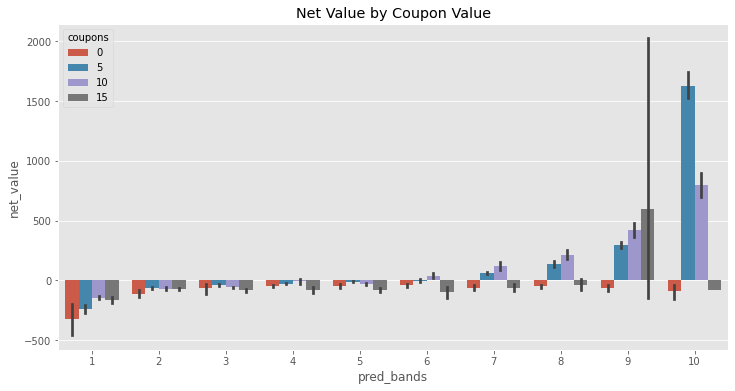

In [15]:
plt.figure(figsize=(12,6))
sns.barplot(data=model(customer_features), x="pred_bands", y="net_value", hue="coupons")
plt.title("Net Value by Coupon Value");

아주 흥미로운 그래프입니다. 최적의 결정이 예측 밴드마다 달라진다는 점에 주목하세요. 예를 들어 1, 7, 8번 밴드에서는 10 BRL 쿠폰을 주는 것이 최선입니다. 3, 5, 10번 밴드에서는 5 BRL 쿠폰이 최선입니다. 즉, 이 정책은 마지막 밴드를 빼면 단순한 정책과 매우 비슷합니다. 최적의 결정이 하위 집단마다 달라지니 개인화가 가능할 수도 있다는 증거입니다.

이 정책을 `if ... then ...` 문 몇 개로 코딩할 수도 있지만, 데이터프레임 연산을 활용하는 좀 더 일반적인 방법을 보여 드리겠습니다.

![img](./data/img/when-prediction-fails/pandas-magic.png)

먼저 위 그래프처럼 고객을 밴드와 쿠폰 금액으로 묶고 그룹별 평균 `net_value`를 구합니다.

In [16]:
pred_bands = (model(customer_features)
              .groupby(["pred_bands", "coupons"])
              [["net_value"]].mean()
              .reset_index())

pred_bands.head(7)

,pred_bands,coupons,net_value
0,1,0,-324.538462
1,1,5,-237.683871
2,1,10,-142.203390
3,1,15,-160.413223
4,2,0,-108.980769
5,2,5,-63.718650
6,2,10,-68.327146


그다음 밴드별로 묶어 행마다 `net_value` 순위를 매깁니다. 그러면 평균 `net_value`에 따라 행의 순서가 정해지고, 그 밴드에서 `net_value`가 가장 높은 행이 1위가 됩니다.

In [17]:
pred_bands["max_net"] = (pred_bands
                         .groupby(['pred_bands'])
                         [["net_value"]]
                         .rank(ascending=False))


pred_bands.head(7)

,pred_bands,coupons,net_value,max_net
0,1,0,-324.538462,4.0
1,1,5,-237.683871,3.0
2,1,10,-142.203390,1.0
3,1,15,-160.413223,2.0
4,2,0,-108.980769,4.0
5,2,5,-63.718650,1.0
6,2,10,-68.327146,2.0


예를 들어 1번 밴드에서 최선의 쿠폰 전략은 10 BRL입니다. 다음으로 밴드마다 `net_value`가 가장 큰 행만 남깁니다.

In [18]:
best_coupons_per_band = pred_bands.query("max_net==1")[["pred_bands", "coupons"]]

best_coupons_per_band

,pred_bands,coupons
2,1,10
5,2,5
9,3,5
14,4,10
17,5,5
22,6,10
26,7,10
30,8,10
35,9,15
37,10,5


정책을 만들기 위해 위의 작은 테이블을 밴드를 키로 삼아 원래 테이블에 다시 조인합니다. 그러면 원래 데이터셋의 각 행에 이 정책 기준으로 최적이라고 보는 쿠폰 금액이 짝지어집니다. 그다음 앞에서와 같은 순서를 유지하도록 `customer_id`로 행을 정렬합니다. `ltv_with_coupons`가 쿠폰 금액을 원래 데이터프레임의 순서대로 인수로 받으므로, 평가할 때 이 정렬이 중요합니다.

In [19]:
coupons_per_id = (model(customer_features)
                 .drop(columns=["coupons"])
                 .merge(best_coupons_per_band, on="pred_bands")
                 [["customer_id", "coupons"]]
                 .sort_values('customer_id'))

coupons_per_id.head()

,customer_id,coupons
0,0,10
1,1,10
788,2,5
1982,3,10
2743,4,5


끝으로 정책을 평가하기 위해 `coupons` 열을 쿠폰 배열로 삼아 `ltv_with_coupons` 함수에 넘깁니다. 그러면 이번에는 이 정책에서 정한 대로 쿠폰을 주었다고 가정하고 데이터를 다시 생성합니다.

In [20]:
transactions_policy_w_model, customer_features_policy_w_model = ltv_with_coupons(
    coupons_per_id[["coupons"]].values.flatten()
)

customer_features_policy_w_model = process_data(transactions_policy_w_model, customer_features_policy_w_model)

customer_features_policy_w_model.head()

,customer_id,region,income,coupons,age,net_value
0,0,18,1025,10,24,-87
1,1,40,1649,10,26,42
2,2,35,2034,5,33,63
3,3,29,1859,10,35,-40
4,4,11,1243,5,26,-26


다시 한번 검산해 보면, 세 번째 고객은 여전히 지역 35, 소득 2034, 나이 33인 그 고객입니다. 쿠폰 금액도 정책에서 정한 대로 5 BRL입니다.

이 정책으로 얼마를 벌 수 있는지 확인하려면 새 데이터셋에서 `net_value`의 평균을 계산하면 됩니다.

In [21]:
policy_w_model_gain = customer_features_policy_w_model["net_value"].mean()
policy_w_model_gain

229.9341

나쁘지 않네요! 이 모델 기반 정책으로 고객당 약 230 BRL을 기대할 수 있습니다. 그런데 잠깐만요! 단순한 정책으로 얼마를 벌었는지 기억나시나요? 두 정책을 나란히 비교해 봅시다.

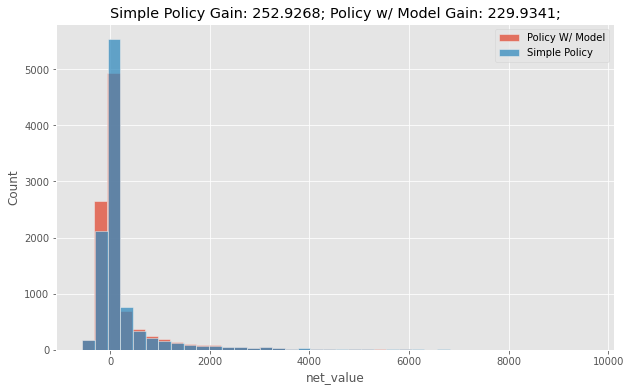

In [22]:
plt.figure(figsize=(10,6))
sns.histplot(data=customer_features_policy_w_model, bins=40,
             x="net_value", label="Policy W/ Model", color="C0")
sns.histplot(data=customer_features_simple_policy, bins=40,
             x="net_value", label="Simple Policy", color="C1")
plt.legend()
plt.title(f"Simple Policy Gain: {simple_policy_gain}; Policy w/ Model Gain: {policy_w_model_gain};");

대부분의 데이터 과학자가 의자에서 굴러떨어지는 대목이 바로 여기입니다. 모델을 활용한 정책의 평균 `net_income`이 아주 단순한 정책보다 20 BRL이나 낮습니다. `net_value`를 잘 예측하는 모델이 어떻게 `net_value`를 최대화하려는 전략에는 쓸모가 없을 수 있을까요? 분명 코드 어딘가에 버그가 있을 겁니다. 뭔가 착각한 게 틀림없어요. 이럴 리가 없습니다! 그런데 알고 보면 지극히 합리적이고 간단한 이유가 있습니다. 다만 이 질문의 답은 무척 중요하니 조금 더 깊이 들어가 볼 가치가 있습니다.

## 예측이라는 망치로 자기 엄지 내리치기

짧게 답하자면, 이 정책으로 무엇을 원하는지, 즉 쿠폰 금액을 조정해 `net_value`를 최적화하려 한다는 점을 이해하는 데 답이 있습니다. 그림으로 나타내 보면, `net_value`가 쿠폰에 대해 이차 함수 모양을 띤다고 생각해도 무리는 아닙니다. 쿠폰 금액을 늘리면 `net_value`는 처음에는 증가하다가 최고점에 이릅니다. 그 뒤로는 쿠폰 금액을 더 늘릴수록 그 금액이 가져오는 가치보다 비용이 더 커집니다.

![img](./data/img/when-prediction-fails/opt-deriv.png)

그러면 최적의 쿠폰 금액을 찾는 것은 `net_value` 함수의 최댓값을 찾는 것과 같습니다. 함수를 미분하고 그 값을 0으로 두면 됩니다(두 번째 그래프). 경제학자라면 가격 책정 문제임을 알아볼 것입니다. 경제학자들(저를 포함해서)이라면 `net_value`의 함수 형태를 가정하고, 그 함수를 미분해 최적화하는 식으로 이 문제에 접근할 것입니다.

이 접근법에는 큰 장점들이 있지만, 그리 일반적이지 않고 가정을 아주 많이 세워야 한다는 게 제 생각입니다. 안타깝게도 현실 데이터는 미분할 수 있는 함수를 품고 오지 않으니, 대개 어느 정도 짐작이 끼어들 수밖에 없습니다. 더 실용적인(어쩌면 덜 우아한) 방법은 여러 쿠폰 금액을 시험해 보고 어떤 금액이 가장 좋은 `net_value`를 내는지 보는 것입니다. 단순한 정책이 하는 일이 정확히 이것입니다. 과거에 일어난 일을 살펴보고, 가장 유망하다고 드러난 처치를 반복합니다.

모델 기반 정책이 하는 일과 비교해 보세요. 모델 기반 정책은 먼저 `net_value`를 예측하는 머신러닝 모델을 학습시킵니다. 그런 다음 예측값에 따라 고객 공간을 분할합니다. 모델이 좋다면, 이는 다음 그래프처럼 공간을 `net_value` 자체로 분할하는 것과 거의 같습니다.

![img](./data/img/when-prediction-fails/model-opt.png)

예측이 좋을수록 이 공간 분할은 목표 변수 `net_income`으로 분할하는 것에 가까워집니다. 그렇게 할 때 무슨 일이 일어나는지 아주 주의 깊게 보세요. 본질적으로 고객을, 예측 대상인 `net_value`가 변하지 않는 집합들로 나누는 셈입니다! 예측 관점에서는 완벽하게 말이 됩니다. 모델이 예측을 잘한다면, 예측값이 같은 점들의 그룹은 `net_value`도 같을 테니까요.

여기까지는 좋습니다. 하지만 이렇게 하면 쿠폰에 따른 `net_value` 함수가 어떻게 보이게 되는지(초록색 선) 살펴보세요. 기울기가 전혀 없도록 납작해집니다. 예측 관점에서는 훌륭한 일입니다. 모델이 `net_income`의 변동을 모두 잡아냈다는 뜻이니까요. 하지만 정책 관점에서는 끔찍한 일입니다. 쿠폰 금액에 따라 `net_income`이 어떻게 달라질지 볼 수 있을 만한 변동이 하나도 남지 않기 때문입니다. `net_income`에 이런 변동이 없으면 쿠폰 금액을 바꿔도 `net_income`에 아무 효과가 없는 것처럼 보이고, 최적화할 여지가 사라집니다. 덧붙이자면 이건 여기서 쓰는 특정한 이차 함수 모양과는 상관없는 일반적인 현상입니다. 좀 더 구체적으로 보여 드리려고 예를 든 것뿐입니다.

![img](./data/img/when-prediction-fails/flat-curves.png)

요약하면, 어떤 변수 $T$로 어떤 변수 $Y$를 최적화하고 싶을 때 $Y$를 예측하는 것은 도움이 되지 않을 뿐 아니라 오히려 정책에 해가 됩니다. 예측으로 정한 데이터 구획 안에서는 $Y$의 분산이 제한되어, $T$가 $Y$를 어떻게 바꾸는지, 즉 탄력성(elasticity) $\frac{\delta Y}{\delta T} $를 추정하는 능력이 떨어지기 때문입니다. 이 장에서 가장 중요한 문단입니다. 이 장의 내용이 모두 여기에 요약되어 있으니, 처음에 이해가 안 되었다면 다시 읽어 보세요.

이 실수를 바로잡는 열쇠는 목표를 정말 원하는 것에 맞추는 데 있습니다. 예측이 하는 것처럼 $X$로 $Y$를 추정하는 대신, $X$로 $\frac{\delta Y}{\delta T} $를 추정해야 합니다. 말이야 쉽지만 하기는 어렵습니다. 이미 짐작했겠지만 이것이 바로 인과추론이 다루는 일입니다. 그리고 인과 문제가 늘 그렇듯 관심 있는 양 $\frac{\delta Y}{\delta T} $는 관측할 수 없습니다. 고객마다 쿠폰을 한 번만 관측하니, 쿠폰 금액을 바꿨다면 `net_income`이 어떻게 변했을지는 그저 관측할 방법이 없습니다. 다른 쿠폰 금액을 주었다면 어떻게 되었을지는 결코 알 수 없습니다(물론 시뮬레이션 데이터를 쓴다면 다르지만, 그건 가르칠 때나 쓸모가 있습니다).

인과 문제의 이런 특성 때문에 질문이 꼬리를 뭅니다. 모델이 추정한다는 값을 볼 수 없는데 모델이 좋은지 어떻게 알 수 있을까요? 그런 모델은 어떻게 검증할까요? 게다가 데이터가 무작위가 아니라면 어떻게 해야 할까요? 편향된 데이터에서 최선의 정책을 어떻게 추정할 수 있을까요? 모두 타당한 질문이고, 때가 되면 답하겠습니다. 그동안 $Y$를 추정하던 데서 $\frac{\delta Y}{\delta T}$를 추정하는 쪽으로 초점을 옮기면 그에 맞춰 많은 것이 바뀌어야 한다는 점을 기억해 두세요. 전통적인 머신러닝 도구도 손볼 곳이 생길 것입니다.


## 예측이 도움이 될 수도 있는 경우

머신러닝이 인과효과를 추론하는 능력을 방해하는 이 모든 혼란은 진짜 목표를 착각한 데서 비롯됩니다. $\frac{\delta Y}{\delta T} $가 아니라 $Y$를 추정한 데서 생기는 것입니다. 하지만 인과추론이 목표인데 예측 모델을 쓰고도 무사히 넘어가는 경우가 실제로 가끔 있습니다. 다만 그러려면 $Y$와 $\frac{\delta Y}{\delta T} $가 어떤 식으로든 상관되어 있어야 합니다. 예를 들어 아래 그림의 두 경우를 생각해 봅시다.


![img](./data/img/when-prediction-fails/waiting-time.png)

첫 번째는 앞에서 본, 쿠폰이 수익성에 미치는 영향을 이해하는 문제입니다. 처음에는 쿠폰 금액을 늘리면 수익성이 높아집니다. 둘이 함께 오르니 양의 상관관계라고 볼 수 있습니다. 게다가 도함수 그래프를 보면, 처음에는 쿠폰 금액을 늘릴수록 탄력성 $\frac{\delta Y}{\delta T} $가 줄어듭니다. 둘을 합쳐 보면, 그래프의 첫 구간에서는 순가치가 커질수록 탄력성이 작아집니다. 즉, 둘은 음의 상관관계입니다.

하지만 그건 처음뿐입니다. 쿠폰 금액을 계속 늘리면 수익성은 낮아지고 수익성의 탄력성도 낮아집니다. 이제 $\frac{\delta Y}{\delta T} $와 $Y$는 양의 상관관계가 됩니다. 결국 결과와 탄력성은 처음에는 음의 상관관계였다가, 쿠폰 금액이 커지면서 그 상관관계가 뒤집힙니다. 결과와 결과의 탄력성 사이에 직접적인 관계가 없으니 여기서는 예측 모델이 도움이 되지 않습니다.

달리 생각해 보면, 예측 모델은 데이터를 $Y$축 방향으로 잘라 냅니다. 이런 식으로 자르면 탄력성이 양수인 구간의 분석단위와 음수인 구간의 분석단위가 한데 섞입니다.

![img](./data/img/when-prediction-fails/slice-1.png)

이번에는 고객 센터 상담원과 연결되기까지 줄을 서서 기다리는 시간이 고객 만족도에 어떤 영향을 미치는지 알고 싶은 두 번째 경우를 생각해 봅시다. 이 경우 고객 만족도는 대기 시간의 처음 몇 분 동안 꽤 빠르게 떨어집니다. 거의 기다리지 않다가 조금이라도 기다려야 하게 되면 고객은 정말 화가 납니다. 하지만 대기 시간이 길어지면 만족도가 이미 너무 낮아서 그 뒤로는 크게 떨어지지 않습니다. 낮은 수준에서 일종의 포화 상태에 이르는 셈입니다.

이 경우가 흥미로운 이유는 $\frac{\delta Y}{\delta T} $와 $Y$의 관계가 크게 바뀌지 않기 때문입니다. 둘은 언제나 음의 상관관계입니다. 대기 시간이 길어지면 만족도는 낮아지고 만족도의 탄력성은 커집니다. 바꿔 말하면 $T$가 커질수록 $\frac{\delta Y}{\delta T} $는 커지고 $Y$는 작아집니다. 이런 경우에는 예측 모델이 쓸모 있을 수 있습니다. 이제는 $Y$축 방향으로 자르면 탄력성이 비슷한 분석단위끼리 묶이기 때문입니다.

![img](./data/img/when-prediction-fails/slice-2.png)

좀 더 일반적으로 말하면, 탄력성이 결과와 대략 같은 방향으로 변하는 함수 형태라면 예측 모델로도 그럭저럭 넘어갈 수 있습니다. 하지만 여기서 조심하세요. 그렇다고 예측 모델이 최선의 선택이라거나 인과 문제에 예측 모델을 써야 한다는 뜻은 아닙니다. 인과적 목표에 통하는 예측 모델을 보게 되었을 때 무슨 일이 일어나고 있는지 이해할 수 있도록 짚어 둘 뿐입니다.

## 그래프로 본 설명

예측 모델이 개인화에 해로울 수 있다는 사실은 너무 직관에 어긋나고 이상해서, 이 문제를 여러 관점에서 다뤄야겠다는 생각이 듭니다. 다음에 나올 그래프 설명은 지금 일어나는 일을 다른 각도에서 이해하는 방법입니다.

아래 그림에서 가장 왼쪽의 인과 그래프를 보세요. 특성 $X$가 결과 $Y$와 처치 $T$를 모두 일으키는 전형적인 교란 그래프입니다. 예측 모델을 만들어 그 예측값으로 분석단위를 세분화하면 어떻게 될까요?

![img](./data/img/when-prediction-fails/graph-1.png)

그러면 왼쪽 그래프들과 비슷한 것을 얻게 됩니다(엄밀히 말하면 더는 인과 그래프가 아닙니다. 모델이 결과를 일으키지는 않으니까요. 모델은 특성에서 결과로 가는 매핑 함수를 학습할 뿐이지만, 그렇다고 지금부터 할 이야기가 틀려지지는 않습니다). 이 모델로 세분화하는 것은 모델 노드를 조건부로 두는 것과 같습니다. 각 세그먼트 안에서 $M(T, X)$를 고정하는 것입니다. 그렇게 해 놓고 $M(T, X)$를 조건부로 둔 채 $T$와 $Y$의 관계를 알아내려 하면, 1부에서 나쁜 통제변수(bad control)를 다루며 본 상황에 빠집니다. 기억나지 않는 분을 위해 다시 말하면, 처치와 결과 사이 경로에 있는 무언가를 통제하면 처치가 결과에 영향을 주는 경로를 막게 됩니다. 그 결과 겉으로 보이는 효과가 실제 효과보다 작아집니다. 자, 바로 이겁니다. 다른 설명으로도 앞에서와 정확히 같은 결론에 도달했습니다. 예측 모델로 분석단위를 세분화하면 인과효과를 식별하는 능력이 떨어집니다.

이쯤에서 눈치 빠른 분이라면 이렇게 반박할 것입니다. 그냥 모델에서 $T$를 빼면 되지 않을까요? 정말 좋은 지적입니다. 너무 좋은 지적이라, 모델을 그런 식으로 속이려는 게 왜 그다지 현명하지 않은지 제대로 설명하기까지 저도 몇 년이 걸렸습니다. 사실 이 장에서 살펴본 예제를 돌아보면, 예측 모델에 `coupon` 처치를 아예 넣지 않았다는 걸 알 수 있습니다. 그래도 예측 모델의 분할이 측정된 탄력성을 수평선으로 짓눌러 버리는 문제는 해결되지 않았습니다. 그 이유는 다음 그림에 있습니다.

![img](./data/img/when-prediction-fails/graph-2.png)

모델 $M(X)$에서 처치 $T$를 빼는 것만으로는 모델이 $T$와 $Y$의 관계를 무시하게 만들 수 없습니다. $X$가 $T$를 일으키므로 모델은 $X$를 통해 $T$를 간접적으로 학습할 수 있습니다. 모델이 왜 그렇게 할까요? $T$가 $Y$를 일으키고 $M$은 $Y$를 최대한 잘 예측하려 하므로, $T$를 $Y$와 이어 주는 $X$ 속 패턴을 어떻게든 활용할 수밖에 없기 때문입니다. 다시 말해 처치가 결과에 어떻게 영향을 미치는지에 관한 정보가 특성을 거쳐 거꾸로 모델로 흘러 들어갑니다. 예를 들어 도시의 특정 지역($X$)에 사는 고객에게만 할인($T$)을 준다고 해 봅시다. 논의를 위해 지역 자체는 매출($Y$)에 아무 영향도 주지 않는다고 가정하겠습니다. 그렇더라도 지역이 $T$를 일으키고, 그 할인이 다시 $Y$를 일으키므로 여전히 예측력을 가집니다. 따라서 모델은 $Y$를 예측하려고 이 사실을 활용할 것입니다.

이 주장을 공정하게 평가하자면, $T$를 주지 않는 것으로 모델을 조금은 속일 수 있습니다. 직접 확인하고 싶다면 예제 코드를 다시 실행하되 이번에는 예측 모델의 특성 목록에 `coupons`를 넣어 보세요. 모델 정책의 성과가 더 나빠질 것입니다. 즉, 모델에 $T$를 주지 않는 것이 많지는 않아도 어느 정도 도움이 된다는 뜻입니다.

마지막으로, 여기서 빠져나갈 방법이 하나 있습니다. $T$가 무작위일 때입니다. 그 아주 특별한 경우에는 예측 모델이 실제로 인과추론에 도움이 될 수 있습니다. 하지만 먼저 왜 해가 되지 않는지부터 이해해 봅시다. $T$가 무작위라면 $X$에서 오는 교란이 모두 배제됩니다. 이 경우 $X$에는 $T$가 어떻게 정해지는지에 관한 정보가 전혀 없습니다.

![img](./data/img/when-prediction-fails/graph-3.png)

그렇게 되면 $M(X)$를 통제하더라도 $T$의 효과는 고스란히 $Y$로 흘러갑니다. 다시 말해 $M(X)$가 고정된 세그먼트 안을 들여다봐도 $Y$는 여전히 $T$ 때문에 변합니다. $M(X)$는 더 이상 $T$를 학습할 방법이 없으므로 그 변동을 통제할 수 없습니다. 그뿐 아니라 이렇게 모델을 조건부로 두면 오히려 평균 처치효과(ATE)를 알아내는 데 도움이 됩니다. 이것도 1부에서 보았습니다. $Y$를 잘 예측하지만 $T$를 일으키지는 않는 변수를 통제하면 인과 추정값의 분산이 줄어듭니다. 직관적으로 말하면, $X$에서 비롯된 $Y$의 변동 상당 부분이 모델을 조건부로 두면서 제거되기 때문입니다. $X$로 설명되는 부분이 걷히고 나면, $Y$가 여전히 변하는 이유는 대부분 $T$ 때문일 것입니다(측정되지 않은 다른 요인 때문일 수도 있지만, 도움이 된다는 요지는 전해졌으리라 봅니다).

다시 말하지만, 이건 인과추론이 목표일 때 예측 모델을 쓰자는 주장이 아닙니다. 실제로 예측 모델로 정한 세그먼트는 ATE를 식별하는 데 도움이 되지만, 그렇다고 구획마다 ATE(또는 탄력성)가 다르다는 뜻은 아닙니다. 탄력성을 추정하는 것만이 아니라, 탄력성이 평균보다 높거나 낮은 세그먼트를 찾아 처치를 개인화하는 것도 목표라는 점을 기억하세요.

> 옮긴이: 원문에는 '왼쪽 그래프들'이라고 되어 있지만, 그림에서 모델 노드가 들어간 것은 가운데와 오른쪽 그래프입니다.

## 핵심 요약 

전통적인 예측 머신러닝으로는 풀 수 없는 문제가 한 부류 통째로 있다는 것을 보았습니다. 인과적 요소가 있는 최적화 문제로, 대개 '이 지표 Y(이익, 고객 만족도, 전환, 비용...)를 최적화하려면 내가 통제할 수 있는 T(가격, 전화 횟수, 할인 등)를 어떻게 설정해야 할까?'라는 형태를 띱니다. 이런 경우에는 예측 모델이 득보다 실이 클 수 있습니다.

이를 증명하기 위해 최적의 쿠폰 금액을 찾아야 하는 예제를 살펴보았습니다. 처음에는 과거 데이터를 보고 어떤 쿠폰 금액이 가장 높은 수익을 냈는지 확인했습니다. 그런 다음 최적이라고 여긴 그 금액을 모든 고객에게 주었습니다. 이 접근법은 평균적으로 가장 좋은 쿠폰 금액(인과추론 용어로는 처치)이 무엇인지에 답합니다. 즉, 고정된 쿠폰 금액 하나만 골라야 한다면 얼마로 해야 하는가입니다. 하지만 그런 제약은 없습니다. 어떤 고객은 낮은 금액의 쿠폰에, 어떤 고객은 높은 금액의 쿠폰에 더 잘 반응한다면 고객마다 쿠폰을 개인화할 수 있습니다. 이를 위해 예측 머신러닝 모델, 즉 고객 각각이 가져올 가치를 예측하는 모델을 만들어 보았습니다. 그리고 모델의 예측값을 바탕으로 쿠폰 금액을 개인화하려 했습니다. 예측값에 따라 고객을 묶고, 그룹마다 어떤 쿠폰 금액이 가장 좋은지 찾았습니다. 그런 다음 그렇게 알아낸 금액을 쿠폰 전략으로 써 보았습니다. 하지만 모든 고객에게 같은 쿠폰 금액을 주는 단순한 전략보다 성과가 나빴습니다. 다시 말해 머신러닝 모델은 쿠폰 금액에 잘 반응하는 고객과 그렇지 않은 고객을 가려내지 못했습니다.

여기서 풀려는 문제가 **개인화** 문제라는 점에 주목하세요. 이 예제에서는 고객마다 어떤 쿠폰 금액이 가장 좋은지 알아내려 했습니다. 좀 더 일반적으로는 '모든 고객에 걸쳐 $Y_i$를 최대화하려면 고객 $i$마다 어떤 결정 $T$를 내리는 것이 가장 좋을까'라는 형태가 됩니다. 쉽게 풀리는 문제는 아닙니다. 하지만 인과추론의 도움을 받으면 풀 수 있습니다.

이 장에서 꼭 가져가셨으면 하는 중요한 점이 하나 있습니다. 먼저, 1부에서 본 인과추론은 여기서 만든 단순한 정책 같은 정책을 설계하는 데 도움이 됩니다. 그런 정책으로는 처치의 평균 인과효과를 추정하고, 평균적으로 가장 잘 통하는 처치를 찾으려 합니다. 이제는 더 큰 욕심을 내 보겠습니다. 평균적으로 가장 좋은 처치가 아니라 고객 한 명 한 명에게 가장 좋은 처치를 원합니다. 개인화란 바로 이런 것이고, 개인화는 인과추론 방법에 크게 기댑니다.

## 참고 자료 

여기에 쓴 내용은 대부분 제 머릿속에서 나온 것입니다. 경험으로 익힌 것들이지요. 그래서 직접 소개할 만한 참고 자료가 따로 없습니다. 이는 곧 좋은 과학이 보통 거치는 학계의 엄밀한 검증을 통과한 내용이 **아니라는** 뜻이기도 합니다. 보시다시피 실제로 잘 작동하는 방법을 이야기하지만, 왜 그런지 설명하는 데는 시간을 많이 들이지 않습니다. 말하자면 길거리 과학인 셈입니다. 그래도 이렇게 공개해서 누구나 검토할 수 있게 해 두었으니, 터무니없는 내용을 발견하면 언제든 이슈를 열어 주세요. 최선을 다해 답하겠습니다.

이 장에 대해서는 알려 드릴 자료가 많지 않습니다. 인과추론으로 풀려는 개인화 문제를 정식화한 훌륭한 논문 하나가 있을 뿐입니다. *Recursive Partitioning for Heterogeneous Causal Effects, Susan Athey and Guido Imbens, 2016*. 그리고 첫 번째 이미지는 Siraj Raval의 유튜브 영상에서 가져왔습니다.

## 기여하기

Causal Inference for the Brave and True는 과학의 통계학이라 할 수 있는 인과추론을 다루는 오픈소스 자료입니다. 파이썬 기반의 무료 소프트웨어만 사용합니다. 금전적으로나 지적으로나 누구나 접근할 수 있는 자료가 되는 것이 목표입니다.
이 책이 가치 있다고 생각해 후원하고 싶다면 [Patreon](https://www.patreon.com/causal_inference_for_the_brave_and_true)을 방문해 주세요. 금전적으로 기여하기 어렵다면 오탈자 수정, 수정 제안, 이해하기 어려웠던 부분에 대한 피드백으로도 도울 수 있습니다. 책 저장소에서 [이슈를 열어](https://github.com/matheusfacure/python-causality-handbook/issues) 주세요. 마지막으로 이 내용이 마음에 들었다면 도움이 될 만한 사람들과 공유하고 [GitHub에서 스타](https://github.com/matheusfacure/python-causality-handbook/stargazers)를 눌러 주세요.

> 옮긴이: 한국어판의 오역이나 오탈자는 [한국어판 이슈 페이지](https://github.com/CausalInferenceLab/Causal-Inference-with-Python/issues)에 알려 주세요. 한국어판이 도움이 되었다면 [한국어판 저장소](https://github.com/CausalInferenceLab/Causal-Inference-with-Python)에도 스타를 부탁드립니다.